# Data and Multicollinearity
Owner: Anupama Singh

Builds the paper's dataset (706 students, 16 features), checks the labels, and tests the features for multicollinearity before any model is trained.

Run order: this notebook, then the four model notebooks, then `anupama_baseline_evaluation.ipynb`.

## 1. Setup and data
Same data as the paper and as the rest of the team: 706 labeled students with no missing values, the paper's 16 features, two targets. The folds are identical to Megha's Random Forest and XGBoost notebooks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
# Data: local copy in data/ if present, otherwise download from the ECRI repository
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL

# Outputs: the repo's results/ folder when run locally, ./results in Colab
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)

# The paper's 16 features (Table 3) and the two Woodcock targets
FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS",
            "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
raw = pd.read_csv(f"{src}/ECRIRawData.csv", low_memory=False)

# Spring scores are used ONLY to compute the gain (regression target), never as features
spring = raw[raw["Time"] == 2.0].set_index("StuID")[list(TARGETS.values())].add_suffix("_spring")

# Labeled students with no missing feature values, as in the paper (706 students)
data = (df[df["RMwidRS_target"].notna()]
        .dropna(subset=FEATURES)
        .join(spring, on="StuID")
        .reset_index(drop=True))
for score in TARGETS.values():
    data[f"{score}_gain"] = data[f"{score}_spring"] - data[score]

X = data[FEATURES]
print(f"Students: {len(data)} | Schools: {data['SchlID'].nunique()} | Features: {len(FEATURES)}")

Students: 706 | Schools: 42 | Features: 16


## 2. The two targets

In [2]:
overview = pd.DataFrame({
    target_name: {"students": len(data),
                  "label 1 (high growth)": int(data[f"{score}_target"].sum()),
                  "share label 1": round(data[f"{score}_target"].mean(), 3),
                  "average gain (points)": round(data[f"{score}_gain"].mean(), 2)}
    for target_name, score in TARGETS.items()})
overview

,Word Identification,Word Attack
students,706.000,706.000
label 1 (high growth),383.000,416.000
share label 1,0.542,0.589
average gain (points),27.790,12.210


### Check: labels follow the paper's rule
Label = 1 when the fall-to-spring gain is above the control group's (`Tx == 0`) average gain. The authors computed that average over all 946 labeled students, before rows with missing features were dropped. This check is not used for training; it confirms we understand the target.

In [3]:
all_labeled = df[df["RMwidRS_target"].notna()].join(spring, on="StuID")
for target_name, score in TARGETS.items():
    gain = all_labeled[f"{score}_spring"] - all_labeled[score]
    control_avg = gain[all_labeled["Tx"] == 0].mean()
    match = ((gain > control_avg).astype(int) == all_labeled[f"{score}_target"]).mean()
    print(f"{target_name}: control-group average gain = {control_avg:.2f}, "
          f"rule matches {match:.1%} of {len(all_labeled)} labels")

Word Identification: control-group average gain = 26.32, rule matches 100.0% of 946 labels
Word Attack: control-group average gain = 10.75, rule matches 100.0% of 946 labels


## 3. Multicollinearity
Multicollinearity means two or more features carry nearly the same information. It does not hurt predictions much, but it makes Logistic and Linear Regression coefficients unstable and hard to read.

### Correlation matrix
Correlation between every pair of features, from -1 to 1.

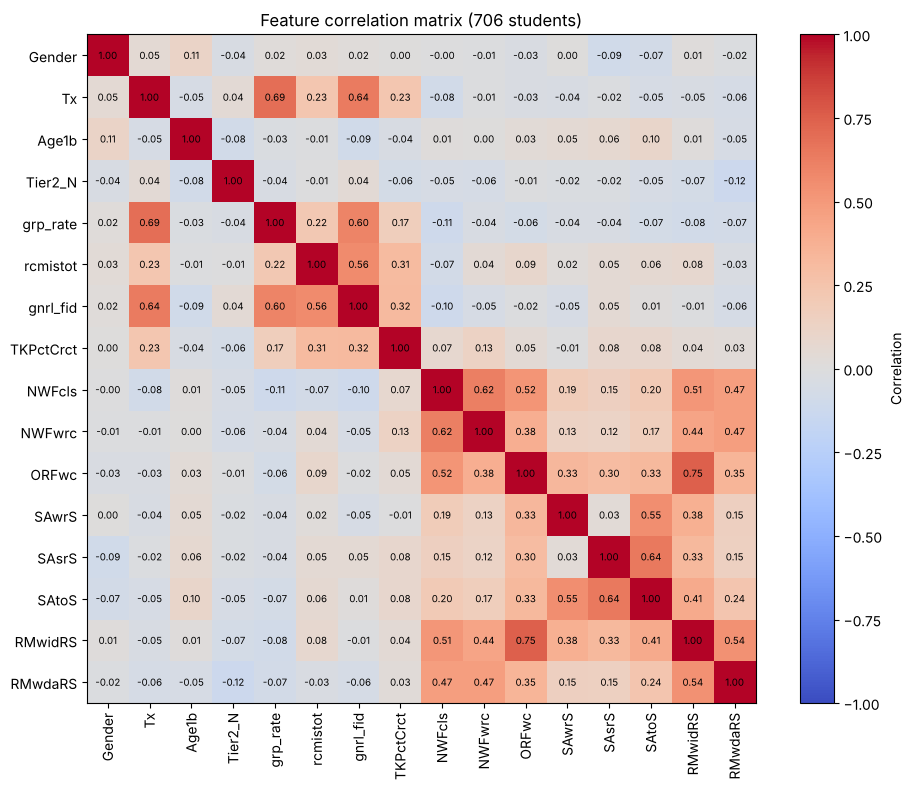

In [4]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for r in range(len(FEATURES)):
    for c in range(len(FEATURES)):
        ax.text(c, r, f"{corr.iloc[r, c]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title(f"Feature correlation matrix ({len(X)} students)")
plt.tight_layout()
plt.savefig(RESULTS / "correlation_matrix.png", dpi=150)
plt.show()

### Strongly correlated pairs (|r| ≥ 0.6)

In [5]:
pairs = [(a, b, round(corr.loc[a, b], 2)) for n, a in enumerate(FEATURES)
         for b in FEATURES[n + 1:] if abs(corr.loc[a, b]) >= 0.6]
pd.DataFrame(pairs, columns=["feature 1", "feature 2", "correlation"]).sort_values(
    "correlation", key=abs, ascending=False).reset_index(drop=True)

,feature 1,feature 2,correlation
0,ORFwc,RMwidRS,0.75
1,Tx,grp_rate,0.69
2,Tx,gnrl_fid,0.64
3,SAsrS,SAtoS,0.64
4,NWFcls,NWFwrc,0.62
5,grp_rate,gnrl_fid,0.60


### Variance inflation factor (VIF)
VIF = 1 / (1 − R²), where R² measures how well a feature is predicted from the other 15. Above 5 is a concern; above 10 is serious.

In [6]:
vif = {}
for f in FEATURES:
    others = [g for g in FEATURES if g != f]
    r2 = LinearRegression().fit(X[others], X[f]).score(X[others], X[f])
    vif[f] = round(1 / (1 - r2), 2)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False)
vif.to_csv(RESULTS / "vif.csv", header=True, index_label="feature")
print(f"Highest VIF: {vif.index[0]} = {vif.iloc[0]} | features with VIF > 5: {int((vif > 5).sum())}")
vif.to_frame()

Highest VIF: SAtoS = 3.41 | features with VIF > 5: 0


,VIF
SAtoS,3.41
RMwidRS,3.17
gnrl_fid,2.81
ORFwc,2.59
SAsrS,2.51
Tx,2.35
SAwrS,2.18
grp_rate,2.17
NWFcls,2.07
NWFwrc,1.84
